In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('/content/IMT2024080_train_var1(in).csv')

print(df.shape)
print(df.columns)
df.head()

(1000, 7)
Index(['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'y'], dtype='object')


,x1,x2,x3,x4,x5,x6,y
0,-0.041961,0.063199,-0.228454,-0.870648,1.000000,1.000000,4.654577
1,0.754401,-0.169469,-1.000000,-0.484070,-1.000000,-1.000000,4.950845
2,0.361623,-0.305213,-0.653325,-0.308226,1.000000,0.267774,-1.276280
3,1.000000,1.000000,0.258402,1.000000,0.790354,0.043688,-3.432147
4,-1.000000,-1.000000,0.478935,-1.000000,0.650325,-0.707147,4.954689


In [5]:
X = df.drop(columns='y')
y = df['y']

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (1000, 6)
y shape: (1000,)


,x1,x2,x3,x4,x5,x6
0,-0.041961,0.063199,-0.228454,-0.870648,1.000000,1.000000
1,0.754401,-0.169469,-1.000000,-0.484070,-1.000000,-1.000000
2,0.361623,-0.305213,-0.653325,-0.308226,1.000000,0.267774
3,1.000000,1.000000,0.258402,1.000000,0.790354,0.043688
4,-1.000000,-1.000000,0.478935,-1.000000,0.650325,-0.707147


In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
degrees = range(1, 11)


In [ ]:
results = []

for degree in degrees:

    fold_mse = []
    fold_r2 = []

    for train_idx, val_idx in kf.split(X):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Generate polynomial features
        poly = PolynomialFeatures(degree=degree, include_bias=False)

        X_train_poly = poly.fit_transform(X_train)
        X_val_poly = poly.transform(X_val)

        # OLS polynomial regression
        model = LinearRegression()
        model.fit(X_train_poly, y_train)

        # Predict validation fold
        y_pred = model.predict(X_val_poly)

        # Evaluate
        fold_mse.append(mean_squared_error(y_val, y_pred))
        fold_r2.append(r2_score(y_val, y_pred))

    results.append({
        'degree': degree,
        'mse': np.mean(fold_mse),
        'r2': np.mean(fold_r2)
    })

In [ ]:
results_df = pd.DataFrame(results)
results_df

,degree,mse,r2
0,1,9.127043,0.098322
1,2,3.428054,0.660794
2,3,1.139398,0.887278
3,4,0.932735,0.907924
4,5,1.343019,0.864763
5,6,93609.242568,-9565.428021
6,7,2000.106866,-209.373125
7,8,490.536511,-51.431421
8,9,178.027825,-17.979846
9,10,95.250340,-9.198667


In [ ]:
best_mse = results_df.loc[results_df['mse'].idxmin()]
best_r2  = results_df.loc[results_df['r2'].idxmax()]

print("Best by MSE:")
print(best_mse)

print("\nBest by R²:")
print(best_r2)

Best by MSE:
degree    4.000000
mse       0.932735
r2        0.907924
Name: 3, dtype: float64

Best by R²:
degree    4.000000
mse       0.932735
r2        0.907924
Name: 3, dtype: float64


In [ ]:
degrees = range(1, 11)
lambdas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

ridge_results = []

for degree in degrees:

    for lam in lambdas:

        fold_mse = []
        fold_r2 = []

        for train_idx, val_idx in kf.split(X):

            X_train = X.iloc[train_idx]
            X_val = X.iloc[val_idx]

            y_train = y.iloc[train_idx]
            y_val = y.iloc[val_idx]

            # 1. Generate polynomial features
            poly = PolynomialFeatures(degree=degree, include_bias=False)

            X_train_poly = poly.fit_transform(X_train)
            X_val_poly = poly.transform(X_val)

            # 2. Standardize polynomial features
            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train_poly)
            X_val_scaled = scaler.transform(X_val_poly)

            # 3. Train Ridge model
            model = Ridge(alpha=lam)
            model.fit(X_train_scaled, y_train)

            # 4. Predict validation fold
            y_pred = model.predict(X_val_scaled)

            # 5. Evaluate
            fold_mse.append(mean_squared_error(y_val, y_pred))
            fold_r2.append(r2_score(y_val, y_pred))

        ridge_results.append({
            'degree': degree,
            'lambda': lam,
            'mse': np.mean(fold_mse),
            'r2': np.mean(fold_r2)
        })

In [ ]:
ridge_df = pd.DataFrame(ridge_results)
ridge_df

,degree,lambda,mse,r2
0,1,0.0001,9.127043,0.098322
1,1,0.0010,9.127043,0.098322
2,1,0.0100,9.127041,0.098322
3,1,0.1000,9.127025,0.098324
4,1,1.0000,9.126864,0.098343
...,...,...,...,...
65,10,0.0100,7.556599,0.220913
66,10,0.1000,6.185112,0.364470
67,10,1.0000,3.771197,0.615157
68,10,10.0000,1.867532,0.809580


In [ ]:
best_ridge_mse = ridge_df.loc[ridge_df['mse'].idxmin()]

print("Best Ridge by MSE:")
print(best_ridge_mse)

Best Ridge by MSE:
degree     5.000000
lambda    10.000000
mse        0.479621
r2         0.952196
Name: 33, dtype: float64


In [ ]:
best_ridge_r2 = ridge_df.loc[ridge_df['r2'].idxmax()]

print("Best Ridge by R²:")
print(best_ridge_r2)

Best Ridge by R²:
degree     5.000000
lambda    10.000000
mse        0.479621
r2         0.952196
Name: 33, dtype: float64


In [ ]:
degrees = range(1, 11)

# Removed 0.001 and 0.0001 to prevent long convergence times and warnings
lambdas = [100, 10, 1, 0.1, 0.01]

lasso_results = []

for degree in degrees:

    # Store results from all 5 folds for each lambda
    mse_by_lambda = {lam: [] for lam in lambdas}
    r2_by_lambda = {lam: [] for lam in lambdas}

    for train_idx, val_idx in kf.split(X):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # 1. Generate polynomial features
        poly = PolynomialFeatures(degree=degree, include_bias=False)

        X_train_poly = poly.fit_transform(X_train)
        X_val_poly = poly.transform(X_val)

        # 2. Standardize using TRAINING data only
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train_poly)
        X_val_scaled = scaler.transform(X_val_poly)

        # 3. Create one LASSO model for this fold
        model = Lasso(
            alpha=lambdas[0],
            max_iter=10000,
            warm_start=True
        )

        # 4. Move from strong -> weak regularization
        for lam in lambdas:

            model.alpha = lam
            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_val_scaled)

            mse_by_lambda[lam].append(
                mean_squared_error(y_val, y_pred)
            )

            r2_by_lambda[lam].append(
                r2_score(y_val, y_pred)
            )

    # 5. Average the 5 folds for every lambda
    for lam in lambdas:

         lasso_results.append({
            'degree': degree,
            'lambda': lam,
            'mse': np.mean(mse_by_lambda[lam]),
            'r2': np.mean(r2_by_lambda[lam])
         })

# Results table
lasso_df = pd.DataFrame(lasso_results)

# Sort just to make the table easier to read
lasso_df = lasso_df.sort_values(
    ['degree', 'lambda']
).reset_index(drop=True)

lasso_df

,degree,lambda,mse,r2
0,1,0.01,9.124590,0.098588
1,1,0.10,9.168451,0.094623
2,1,1.00,10.174607,-0.004508
3,1,10.00,10.174607,-0.004508
4,1,100.00,10.174607,-0.004508
5,2,0.01,3.421435,0.661571
6,2,0.10,3.586195,0.645734
7,2,1.00,8.701502,0.142306
8,2,10.00,10.174607,-0.004508
9,2,100.00,10.174607,-0.004508


In [ ]:
best_lasso_mse = lasso_df.loc[lasso_df['mse'].idxmin()]
best_lasso_r2  = lasso_df.loc[lasso_df['r2'].idxmax()]

print("Best LASSO by MSE:")
print(best_lasso_mse)

print("\nBest LASSO by R²:")
print(best_lasso_r2)

Best LASSO by MSE:
degree    5.000000
lambda    0.010000
mse       0.310742
r2        0.969201
Name: 20, dtype: float64

Best LASSO by R²:
degree    5.000000
lambda    0.010000
mse       0.310742
r2        0.969201
Name: 20, dtype: float64


In [ ]:
degrees = [4, 5, 6]

# Fine-grained lambda search
lambdas = np.arange(0.030, 0.001, -0.001)

lasso_fine_results = []

for degree in degrees:

    mse_by_lambda = {lam: [] for lam in lambdas}
    r2_by_lambda = {lam: [] for lam in lambdas}

    for train_idx, val_idx in kf.split(X):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Polynomial features
        poly = PolynomialFeatures(
            degree=degree,
            include_bias=False
        )

        X_train_poly = poly.fit_transform(X_train)
        X_val_poly = poly.transform(X_val)

        # Standardization
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train_poly)
        X_val_scaled = scaler.transform(X_val_poly)

        # Warm-start LASSO
        model = Lasso(
            alpha=lambdas[0],
            max_iter=30000,
            warm_start=True
        )

        for lam in lambdas:

            model.alpha = lam
            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_val_scaled)

            mse_by_lambda[lam].append(
                mean_squared_error(y_val, y_pred)
            )

            r2_by_lambda[lam].append(
                r2_score(y_val, y_pred)
            )

    for lam in lambdas:

        lasso_fine_results.append({
            'degree': degree,
            'lambda': lam,
            'mse': np.mean(mse_by_lambda[lam]),
            'r2': np.mean(r2_by_lambda[lam])
        })


lasso_fine_df = pd.DataFrame(lasso_fine_results)

In [ ]:
best_mse = lasso_fine_df.loc[
    lasso_fine_df['mse'].idxmin()
]

best_r2 = lasso_fine_df.loc[
    lasso_fine_df['r2'].idxmax()
]

print("Best by MSE:")
print(best_mse)

print("\nBest by R²:")
print(best_r2)

Best by MSE:
degree    5.00000
lambda    0.00900
mse       0.31072
r2        0.96919
Name: 50, dtype: float64

Best by R²:
degree    5.000000
lambda    0.010000
mse       0.310732
r2        0.969202
Name: 49, dtype: float64


FINAL RESULTS

Best by MSE:
lambda    0.009750
mse       0.310716
r2        0.969201
Name: 11, dtype: float64

Best by R²:
lambda    0.009750
mse       0.310716
r2        0.969201
Name: 11, dtype: float64

Full results:


,lambda,mse,r2
0,0.00700,0.311669,0.969075
1,0.00725,0.311240,0.969120
2,0.00750,0.310992,0.969147
3,0.00775,0.310945,0.969155
4,0.00800,0.310859,0.969165
5,0.00825,0.310785,0.969175
6,0.00850,0.310754,0.969181
7,0.00875,0.310754,0.969184
8,0.00900,0.310774,0.969186
9,0.00925,0.310756,0.969191


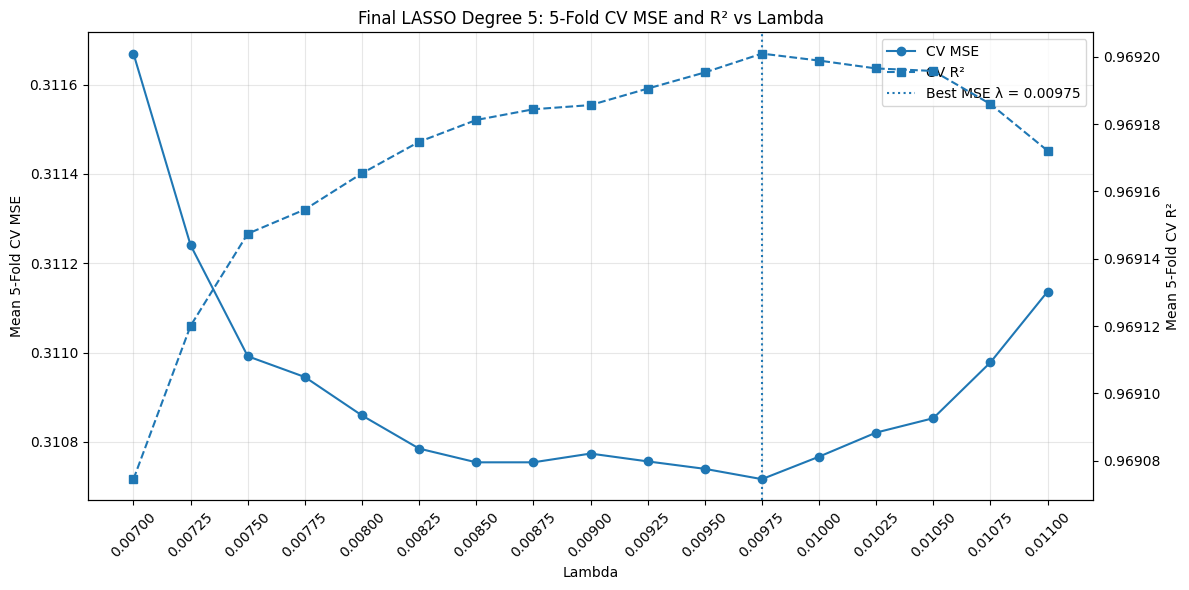

In [ ]:
# ============================================================
# FINAL FINE-TUNING OF LASSO
# Degree = 5
# Lambda = 0.007 to 0.011 with step 0.00025
# 5-Fold Cross Validation
# ============================================================

degree = 5

# Descending order because warm_start works from stronger -> weaker regularization
lambdas = np.arange(0.011, 0.0069, -0.00025)

mse_by_lambda = {lam: [] for lam in lambdas}
r2_by_lambda = {lam: [] for lam in lambdas}


# -------------------------
# 5-Fold Cross Validation
# -------------------------

for train_idx, val_idx in kf.split(X):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # 1. Polynomial features
    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_train_poly = poly.fit_transform(X_train)
    X_val_poly = poly.transform(X_val)

    # 2. Standardization
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_poly)
    X_val_scaled = scaler.transform(X_val_poly)

    # 3. LASSO with warm start
    model = Lasso(
        alpha=lambdas[0],
        max_iter=30000,
        warm_start=True
    )

    # 4. Test each lambda
    for lam in lambdas:

        model.alpha = lam
        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_val_scaled)

        mse_by_lambda[lam].append(
            mean_squared_error(y_val, y_pred)
        )

        r2_by_lambda[lam].append(
            r2_score(y_val, y_pred)
        )


# -------------------------
# Average across 5 folds
# -------------------------

final_results = []

for lam in lambdas:

    final_results.append({
        'lambda': lam,
        'mse': np.mean(mse_by_lambda[lam]),
        'r2': np.mean(r2_by_lambda[lam])
    })


final_df = pd.DataFrame(final_results)

# Sort lambda from smallest -> largest for display/plotting
final_df = final_df.sort_values('lambda').reset_index(drop=True)


# -------------------------
# Find optimum
# -------------------------

best_mse = final_df.loc[
    final_df['mse'].idxmin()
]

best_r2 = final_df.loc[
    final_df['r2'].idxmax()
]


print("FINAL RESULTS")
print("=" * 40)

print("\nBest by MSE:")
print(best_mse)

print("\nBest by R²:")
print(best_r2)

print("\nFull results:")
display(final_df)


# ============================================================
# PLOT MSE AND R² TOGETHER
# ============================================================

fig, ax1 = plt.subplots(figsize=(12, 6))


# ---- MSE: left Y-axis ----

line1 = ax1.plot(
    final_df['lambda'],
    final_df['mse'],
    'o-',
    label='CV MSE'
)

ax1.set_xlabel('Lambda')
ax1.set_ylabel('Mean 5-Fold CV MSE')


# ---- R²: right Y-axis ----

ax2 = ax1.twinx()

line2 = ax2.plot(
    final_df['lambda'],
    final_df['r2'],
    's--',
    label='CV R²'
)

ax2.set_ylabel('Mean 5-Fold CV R²')


# ---- Mark best MSE lambda ----

best_lambda_mse = best_mse['lambda']

best_line = ax1.axvline(
    best_lambda_mse,
    linestyle=':',
    label=f'Best MSE λ = {best_lambda_mse:.5f}'
)


# ---- Mark best R² lambda if different ----

if not np.isclose(best_mse['lambda'], best_r2['lambda']):

    best_r2_line = ax1.axvline(
        best_r2['lambda'],
        linestyle='--',
        label=f'Best R² λ = {best_r2["lambda"]:.5f}'
    )

else:
    best_r2_line = None


# ---- Show every tested lambda ----

ax1.set_xticks(final_df['lambda'])
ax1.set_xticklabels(
    [f'{x:.5f}' for x in final_df['lambda']],
    rotation=45
)


# ---- Combined legend ----

lines = line1 + line2 + [best_line]

if best_r2_line is not None:
    lines.append(best_r2_line)

labels = [line.get_label() for line in lines]

ax1.legend(lines, labels, loc='best')


ax1.grid(alpha=0.3)

plt.title(
    'Final LASSO Degree 5: '
    '5-Fold CV MSE and R² vs Lambda'
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# RETRAIN FINAL OPTIMAL MODEL ON ALL 1000 ROWS
# ============================================================

best_deg = 5
best_lam = 0.00975

# 1. Generate features for all 1000 rows of X
final_poly = PolynomialFeatures(degree=best_deg, include_bias=False)
X_poly_all = final_poly.fit_transform(X)

# 2. Fit scaler on all 1000 rows
final_scaler = StandardScaler()
X_scaled_all = final_scaler.fit_transform(X_poly_all)

# 3. Train final Lasso model on the entire dataset using consistent default settings
final_model = Lasso(alpha=best_lam, max_iter=50000)
final_model.fit(X_scaled_all, y)

# Count how many features Lasso selected (non-zero coefficients)
active_features = np.sum(final_model.coef_ != 0)
total_features = X_scaled_all.shape[1]

print("--- Final Model Training Complete ---")
print(f"Total features generated: {total_features}")
print(f"Features kept by LASSO (non-zero): {active_features}")
print(f"Intercept: {final_model.intercept_:.5f}")

--- Final Model Training Complete ---
Total features generated: 461
Features kept by LASSO (non-zero): 108
Intercept: 0.95625


In [ ]:
# Load the test dataset and sample submission template
test_df = pd.read_csv('/content/IMT2024080_test_var1(in).csv')
sample_submission = pd.read_csv('/content/sample_submission.csv')

print("Test Data Shape:", test_df.shape)
print("Sample Submission Shape:", sample_submission.shape)

Test Data Shape: (1000, 6)
Sample Submission Shape: (1000, 1)


In [ ]:
print("Iterations used:", final_model.n_iter_)

Iterations used: 273


In [ ]:
# ============================================================
# PREDICT TEST SET AND CREATE SUBMISSION CSV
# ============================================================

# 1. Apply the SAME degree-5 polynomial transformation
#    learned/defined during final training
X_test_poly = final_poly.transform(test_df)

# 2. Apply the SAME scaler fitted on the 1000 training samples
X_test_scaled = final_scaler.transform(X_test_poly)

# 3. Predict y using the final LASSO model
y_pred = final_model.predict(X_test_scaled)

# 4. Put predictions into the sample-submission format
submission = sample_submission.copy()
submission['y'] = y_pred

# 5. Save as CSV
output_path = '/content/IMT2024080_predictions_var1.csv'
submission.to_csv(output_path, index=False)

# 6. Sanity checks
print("Test rows:       ", len(test_df))
print("Predictions:     ", len(y_pred))
print("Submission rows: ", len(submission))
print("Missing values:  ", submission['y'].isna().sum())

print("\nFirst 10 predictions:")
display(submission.head(10))

print("\nSaved to:", output_path)

Test rows:        1000
Predictions:      1000
Submission rows:  1000
Missing values:   0

First 10 predictions:


,y
0,-2.287197
1,-1.914601
2,3.752594
3,-2.677265
4,-6.324707
5,4.516118
6,0.499913
7,-3.522495
8,-0.027953
9,6.415754



Saved to: /content/IMT2024080_predictions_var1.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from google.colab import files

# Download the generated predictions CSV to your laptop
files.download('/content/IMT2024080_predictions_var1.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

=== Summary Statistics Comparison ===


,Training Target (y),Predicted Target (y_pred)
count,1000.000000,1000.000000
mean,0.956253,1.080017
std,3.188689,4.293104
min,-9.281842,-10.457118
25%,-1.031929,-1.702834
50%,0.784278,0.952549
75%,2.874891,3.980816
max,14.718050,16.371537


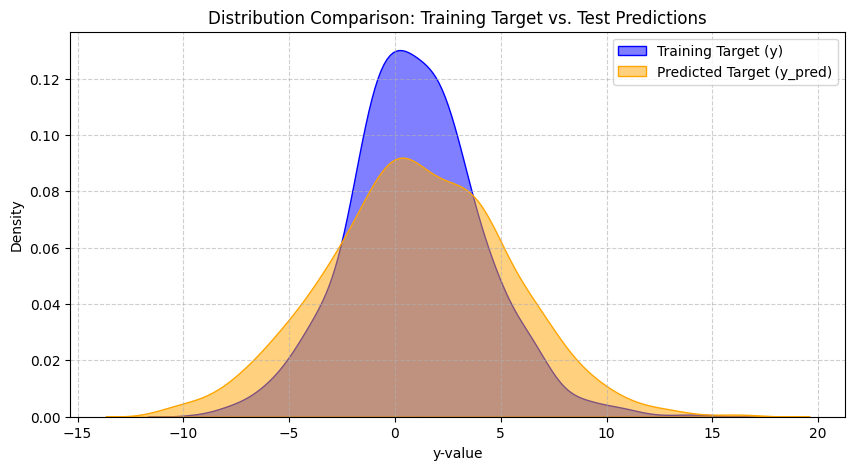

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the predictions we just saved
preds_df = pd.read_csv('/content/IMT2024080_predictions_var1.csv')

# Print summary statistics comparison
print("=== Summary Statistics Comparison ===")
stats_comparison = pd.DataFrame({
    'Training Target (y)': y.describe(),
    'Predicted Target (y_pred)': preds_df['y'].describe()
})
display(stats_comparison)

# Plot distribution comparison
plt.figure(figsize=(10, 5))
sns.kdeplot(y, label='Training Target (y)', fill=True, color='blue', alpha=0.5)
sns.kdeplot(preds_df['y'], label='Predicted Target (y_pred)', fill=True, color='orange', alpha=0.5)
plt.title('Distribution Comparison: Training Target vs. Test Predictions')
plt.xlabel('y-value')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

OOF MSE: 0.31076
OOF R²:  0.96941


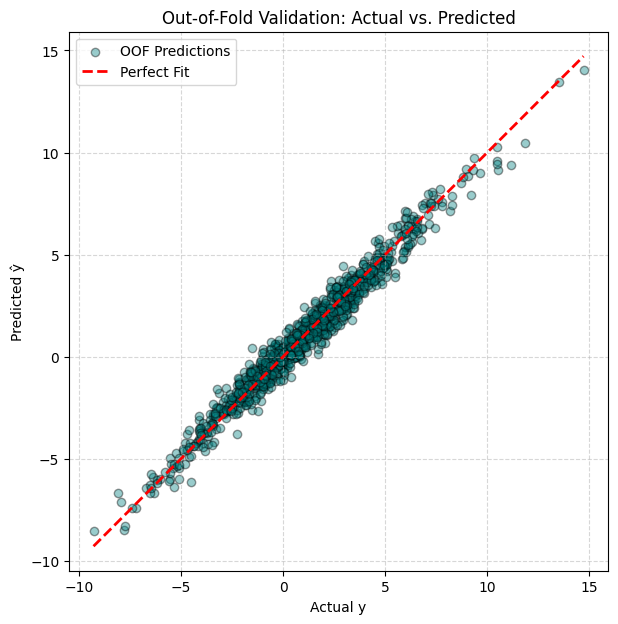

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Define the clean cross-validation pipeline
oof_model = Pipeline([
    ('poly', PolynomialFeatures(degree=5, include_bias=False)),
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.00975, max_iter=50000))
])

# Generate out-of-fold predictions
y_oof_pred = cross_val_predict(oof_model, X, y, cv=kf)

oof_mse = mean_squared_error(y, y_oof_pred)
oof_r2 = r2_score(y, y_oof_pred)

print(f"OOF MSE: {oof_mse:.5f}")
print(f"OOF R²:  {oof_r2:.5f}")

# Plot the diagnostic fit
plt.figure(figsize=(7, 7))
plt.scatter(y, y_oof_pred, alpha=0.4, color='teal', edgecolors='k', label='OOF Predictions')
lims = [min(y.min(), y_oof_pred.min()), max(y.max(), y_oof_pred.max())]
plt.plot(lims, lims, color='red', linestyle='--', linewidth=2, label='Perfect Fit')
plt.title('Out-of-Fold Validation: Actual vs. Predicted')
plt.xlabel('Actual y')
plt.ylabel('Predicted ŷ')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.gca().set_aspect('equal', 'box')
plt.show()

In [7]:
# ============================================================
# VAR1 — ELASTIC NET 5-FOLD CROSS VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# 1. Hyperparameter grid
elastic_degrees = [3, 4, 5, 6]
elastic_alphas = [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1]
elastic_ratios = [0.1, 0.25, 0.5, 0.75, 0.9]

# Reuse VAR1 data X, y and CV splitter kf
elastic_var1_results = []

for degree in elastic_degrees:

    print(f"Processing degree {degree}...", flush=True)

    # 2. Prepare each fold only once per degree
    fold_data = []

    for train_idx, val_idx in kf.split(X):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Polynomial features
        poly = PolynomialFeatures(
            degree=degree,
            include_bias=False
        )

        X_train_poly = poly.fit_transform(X_train)
        X_val_poly = poly.transform(X_val)

        # Standardize using training fold only
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train_poly)
        X_val_scaled = scaler.transform(X_val_poly)

        fold_data.append((
            X_train_scaled,
            X_val_scaled,
            y_train,
            y_val
        ))

    # 3. Search alpha and L1 ratio
    for alpha in elastic_alphas:

        for ratio in elastic_ratios:

            fold_mse = []
            fold_r2 = []
            fold_iters = []
            warning_count = 0

            for X_tr, X_val, y_tr, y_val in fold_data:

                model = ElasticNet(
                    alpha=alpha,
                    l1_ratio=ratio,
                    max_iter=30000,
                    tol=1e-5,
                    selection='cyclic'
                )

                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter(
                        "always", ConvergenceWarning
                    )
                    model.fit(X_tr, y_tr)

                warning_count += sum(
                    issubclass(w.category, ConvergenceWarning)
                    for w in caught
                )

                y_pred = model.predict(X_val)

                fold_mse.append(
                    mean_squared_error(y_val, y_pred)
                )

                fold_r2.append(
                    r2_score(y_val, y_pred)
                )

                fold_iters.append(model.n_iter_)

            elastic_var1_results.append({
                'degree': degree,
                'alpha': alpha,
                'l1_ratio': ratio,
                'mse': np.mean(fold_mse),
                'r2': np.mean(fold_r2),
                'max_iterations': max(fold_iters),
                'warnings': warning_count
            })

# ============================================================
# RESULTS
# ============================================================

elastic_var1_df = pd.DataFrame(elastic_var1_results)

best_elastic_var1 = elastic_var1_df.loc[
    elastic_var1_df['mse'].idxmin()
]

best_elastic_var1_r2 = elastic_var1_df.loc[
    elastic_var1_df['r2'].idxmax()
]

print("\n=== VAR1 BEST ELASTIC NET BY MSE ===")
print(best_elastic_var1)

print("\n=== VAR1 BEST ELASTIC NET BY R² ===")
print(best_elastic_var1_r2)

print("\n=== TOP 10 CONFIGURATIONS ===")
display(
    elastic_var1_df.sort_values('mse').head(10)
)

print("\n=== CONVERGENCE CHECK ===")
print(
    "Configurations with warnings:",
    (elastic_var1_df['warnings'] > 0).sum()
)

print("\n=== CURRENT LASSO BENCHMARK ===")
print("LASSO CV MSE: 0.310742")
print("LASSO CV R²: 0.969201")

Processing degree 3...
Processing degree 4...
Processing degree 5...
Processing degree 6...

=== VAR1 BEST ELASTIC NET BY MSE ===
degree              5.000000
alpha               0.010000
l1_ratio            0.900000
mse                 0.311835
r2                  0.969084
max_iterations    492.000000
warnings            0.000000
Name: 79, dtype: float64

=== VAR1 BEST ELASTIC NET BY R² ===
degree              5.000000
alpha               0.010000
l1_ratio            0.900000
mse                 0.311835
r2                  0.969084
max_iterations    492.000000
warnings            0.000000
Name: 79, dtype: float64

=== TOP 10 CONFIGURATIONS ===


,degree,alpha,l1_ratio,mse,r2,max_iterations,warnings
79,5,0.010,0.90,0.311835,0.969084,492,0
78,5,0.010,0.75,0.314227,0.968840,589,0
74,5,0.005,0.90,0.317303,0.968478,813,0
73,5,0.005,0.75,0.318745,0.968321,1025,0
77,5,0.010,0.50,0.323857,0.967850,1014,0
109,6,0.010,0.90,0.328599,0.967472,921,0
72,5,0.005,0.50,0.328610,0.967316,1681,0
108,6,0.010,0.75,0.333393,0.966967,1014,0
104,6,0.005,0.90,0.340587,0.966182,1665,0
76,5,0.010,0.25,0.340771,0.966101,1980,0



=== CONVERGENCE CHECK ===
Configurations with warnings: 10

=== CURRENT LASSO BENCHMARK ===
LASSO CV MSE: 0.310742
LASSO CV R²: 0.969201
